In [1]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math
import datetime

from scipy import signal
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t as t_dist
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
import matplotlib.colors as mplcolors
from matplotlib.ticker import FixedLocator
from matplotlib.ticker import AutoMinorLocator
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch, Rectangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

Importing Library
done


In [2]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [3]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [4]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492.0E+3          # JUPITER RADIUS [m]

# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

In [5]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b5_v2_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')
case = 'Case II'
linecolor = UC.pink

In [6]:
# %% Juno's perijove times
JUNO_PJ_TIMES = [
    datetime.datetime.strptime(
        '2016-08-27 12:50', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2016-10-19 18:10', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2016-12-11 17:03', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-02-02 12:57', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-03-27 08:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-05-19 06:00', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-07-11 01:54', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-09-01 21:48', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-10-24 17:42', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-12-16 17:56', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-02-07 13:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-04-01 09:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-05-24 05:39', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-07-16 05:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-09-07 01:11', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-10-29 21:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-12-21 16:59', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-02-12 17:34', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-04-06 12:14', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-05-29 08:08', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-07-21 04:02', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-09-12 03:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-11-03 22:18', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-12-26 17:36', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-02-17 17:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-04-10 13:47', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-06-02 10:20', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-07-25 06:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-09-16 02:10', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-11-08 01:49', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-12-30 21:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-02-21 17:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-04-15 23:32', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-06-08 07:46', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-07-21 08:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-09-02 22:42', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-10-16 17:13', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-11-29 14:13', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-01-12 10:33', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-02-25 01:59', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-04-09 15:49', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-05-23 02:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-07-05 09:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-08-17 14:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-09-29 17:11', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime('2022-11-06', '%Y-%m-%d'),  # PJ46
    datetime.datetime.strptime('2022-12-15', '%Y-%m-%d'),  # PJ47
    datetime.datetime.strptime('2023-01-22', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-03-01', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-04-08', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-05-16', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-06-23', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-07-31', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-09-07', '%Y-%m-%d'),  # PJ54
    datetime.datetime.strptime('2023-10-15', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-11-22', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-12-30', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-02-04', '%Y-%m-%d'),  # PJ58
    datetime.datetime.strptime('2024-03-07', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-04-09', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-05-12', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-06-14', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-07-16', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-08-18', '%Y-%m-%d'),  # PJ64
    datetime.datetime.strptime('2024-09-20', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-10-22', '%Y-%m-%d'),  # PJ66
    datetime.datetime.strptime(
        '2024-11-24 13:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2024-12-27 05:22', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-01-28 23:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-03-02 16:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-04-04 09:30', '%Y-%m-%d %H:%M'),             # PJ71
    datetime.datetime.strptime(
        '2025-05-07 03:01', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-06-08 20:30', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-07-11 13:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-08-13 07:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-09-14 23:52', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-10-17 16:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-11-19 08:37', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-12-22 01:14', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2026-01-23 17:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2026-02-25 09:32', '%Y-%m-%d %H:%M'),
]
JUNO_PJ_LABELS = ['PJ1', '', '', '', '',
                  '6', '', '', '', '',
                  '11', '', '', '', '',
                  '16', '', '', '', '',
                  '21', '', '', '', '',
                  '26', '', '', '', '',
                  '31', '', '', '', '',
                  '36', '', '', '', '',
                  '41', '', '', '', '',
                  '46', '', '', '', '',
                  '51', '', '', '', '',
                  '56', '', '', '', '',
                  '61', '', '', '', '',
                  '66', '', '', '', '',
                  '71', '', '', '', '',
                  '76', '', '', '', '',
                  '81',]

In [7]:
print(len(JUNO_PJ_TIMES))

81


In [8]:
import pandas as pd

df = pd.read_csv(
    '/Users/shin/Documents/Research/Hisaki/output_Juno20RJ_HisakiRcomp_1monthLag.csv',
)

print(df)

hisaki_pj = df['orbit'].to_numpy()
hisaki_R_comp = df['R_comp'].to_numpy()
hisaki_R_comp_err = df['error_R_comp'].to_numpy()
juno_heavy_ion = df['density_20RJ'].to_numpy()
juno_heavy_ion_err_n = df['density_20RJ_err_n'].to_numpy()
juno_heavy_ion_err_p = df['density_20RJ_err_p'].to_numpy()

hisaki_time = []
for i in range(hisaki_pj.size):
    hisaki_time += [JUNO_PJ_TIMES[hisaki_pj[i]-1]]
hisaki_time = np.array(hisaki_time)

    decimal_year  ion_density  ion_density_err    R_comp  error_R_comp  orbit  \
0    2017.223135     0.272336         0.180178  1.128429      0.077961      5   
1    2017.368241     0.535767         0.106590  1.573429      0.137780      6   
2    2017.513347     0.756274         0.075790       NaN           NaN      7   
3    2017.659822     0.494997         0.062947  2.225625      0.118642      8   
4    2017.806297     0.594346         0.127505  1.811571      0.203413      9   
5    2017.948665    -0.059274         0.111042       NaN           NaN     10   
6    2018.094456     0.361814         0.044902  2.581833      0.183407     11   
7    2018.239562    -0.311411         0.041854  0.650111      0.056700     12   
8    2018.387406     0.616773         0.053660       NaN           NaN     13   
9    2018.528405     0.315255         0.062899  2.099750      0.100683     14   
10   2018.673511     0.002727         0.039538       NaN           NaN     15   
11   2018.819986     0.48199

In [9]:
df = pd.read_csv(
    '/Users/shin/Documents/Research/Hisaki/hisaki_l2p_Slice_check.csv',
)

print(df)

hisaki_1day_datetime = df['datetime']
hisaki_1day_R_comp_dusk = df['R_comp_dusk'].to_numpy()
hisaki_1day_R_comp_dusk_err = df['R_comp_dusk_err'].to_numpy()
hisaki_1day_R_comp_dawn = df['R_comp_dawn'].to_numpy()
hisaki_1day_R_comp_dawn_err = df['R_comp_dawn_err'].to_numpy()

for i in range(len(hisaki_1day_datetime)):
    hisaki_1day_datetime[i] = datetime.datetime.strptime(
        hisaki_1day_datetime[i], '%Y-%m-%d')

        datetime  R_hele_dusk  R_hele_dusk_err  R_hele_dawn  R_hele_dawn_err  \
0     2013-12-01          NaN              NaN          NaN              NaN   
1     2013-12-02          NaN              NaN          NaN              NaN   
2     2013-12-03          NaN              NaN          NaN              NaN   
3     2013-12-04          NaN              NaN          NaN              NaN   
4     2013-12-05          NaN              NaN          NaN              NaN   
...          ...          ...              ...          ...              ...   
3645  2023-11-24          NaN              NaN          NaN              NaN   
3646  2023-11-25          NaN              NaN          NaN              NaN   
3647  2023-11-26          NaN              NaN          NaN              NaN   
3648  2023-11-27          NaN              NaN          NaN              NaN   
3649  2023-11-28          NaN              NaN          NaN              NaN   

      R_comp_dusk  R_comp_dusk_err  R_c

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_33972/2891325008.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hisaki_1day_datetime[i] = datetime.datetime.strptime(


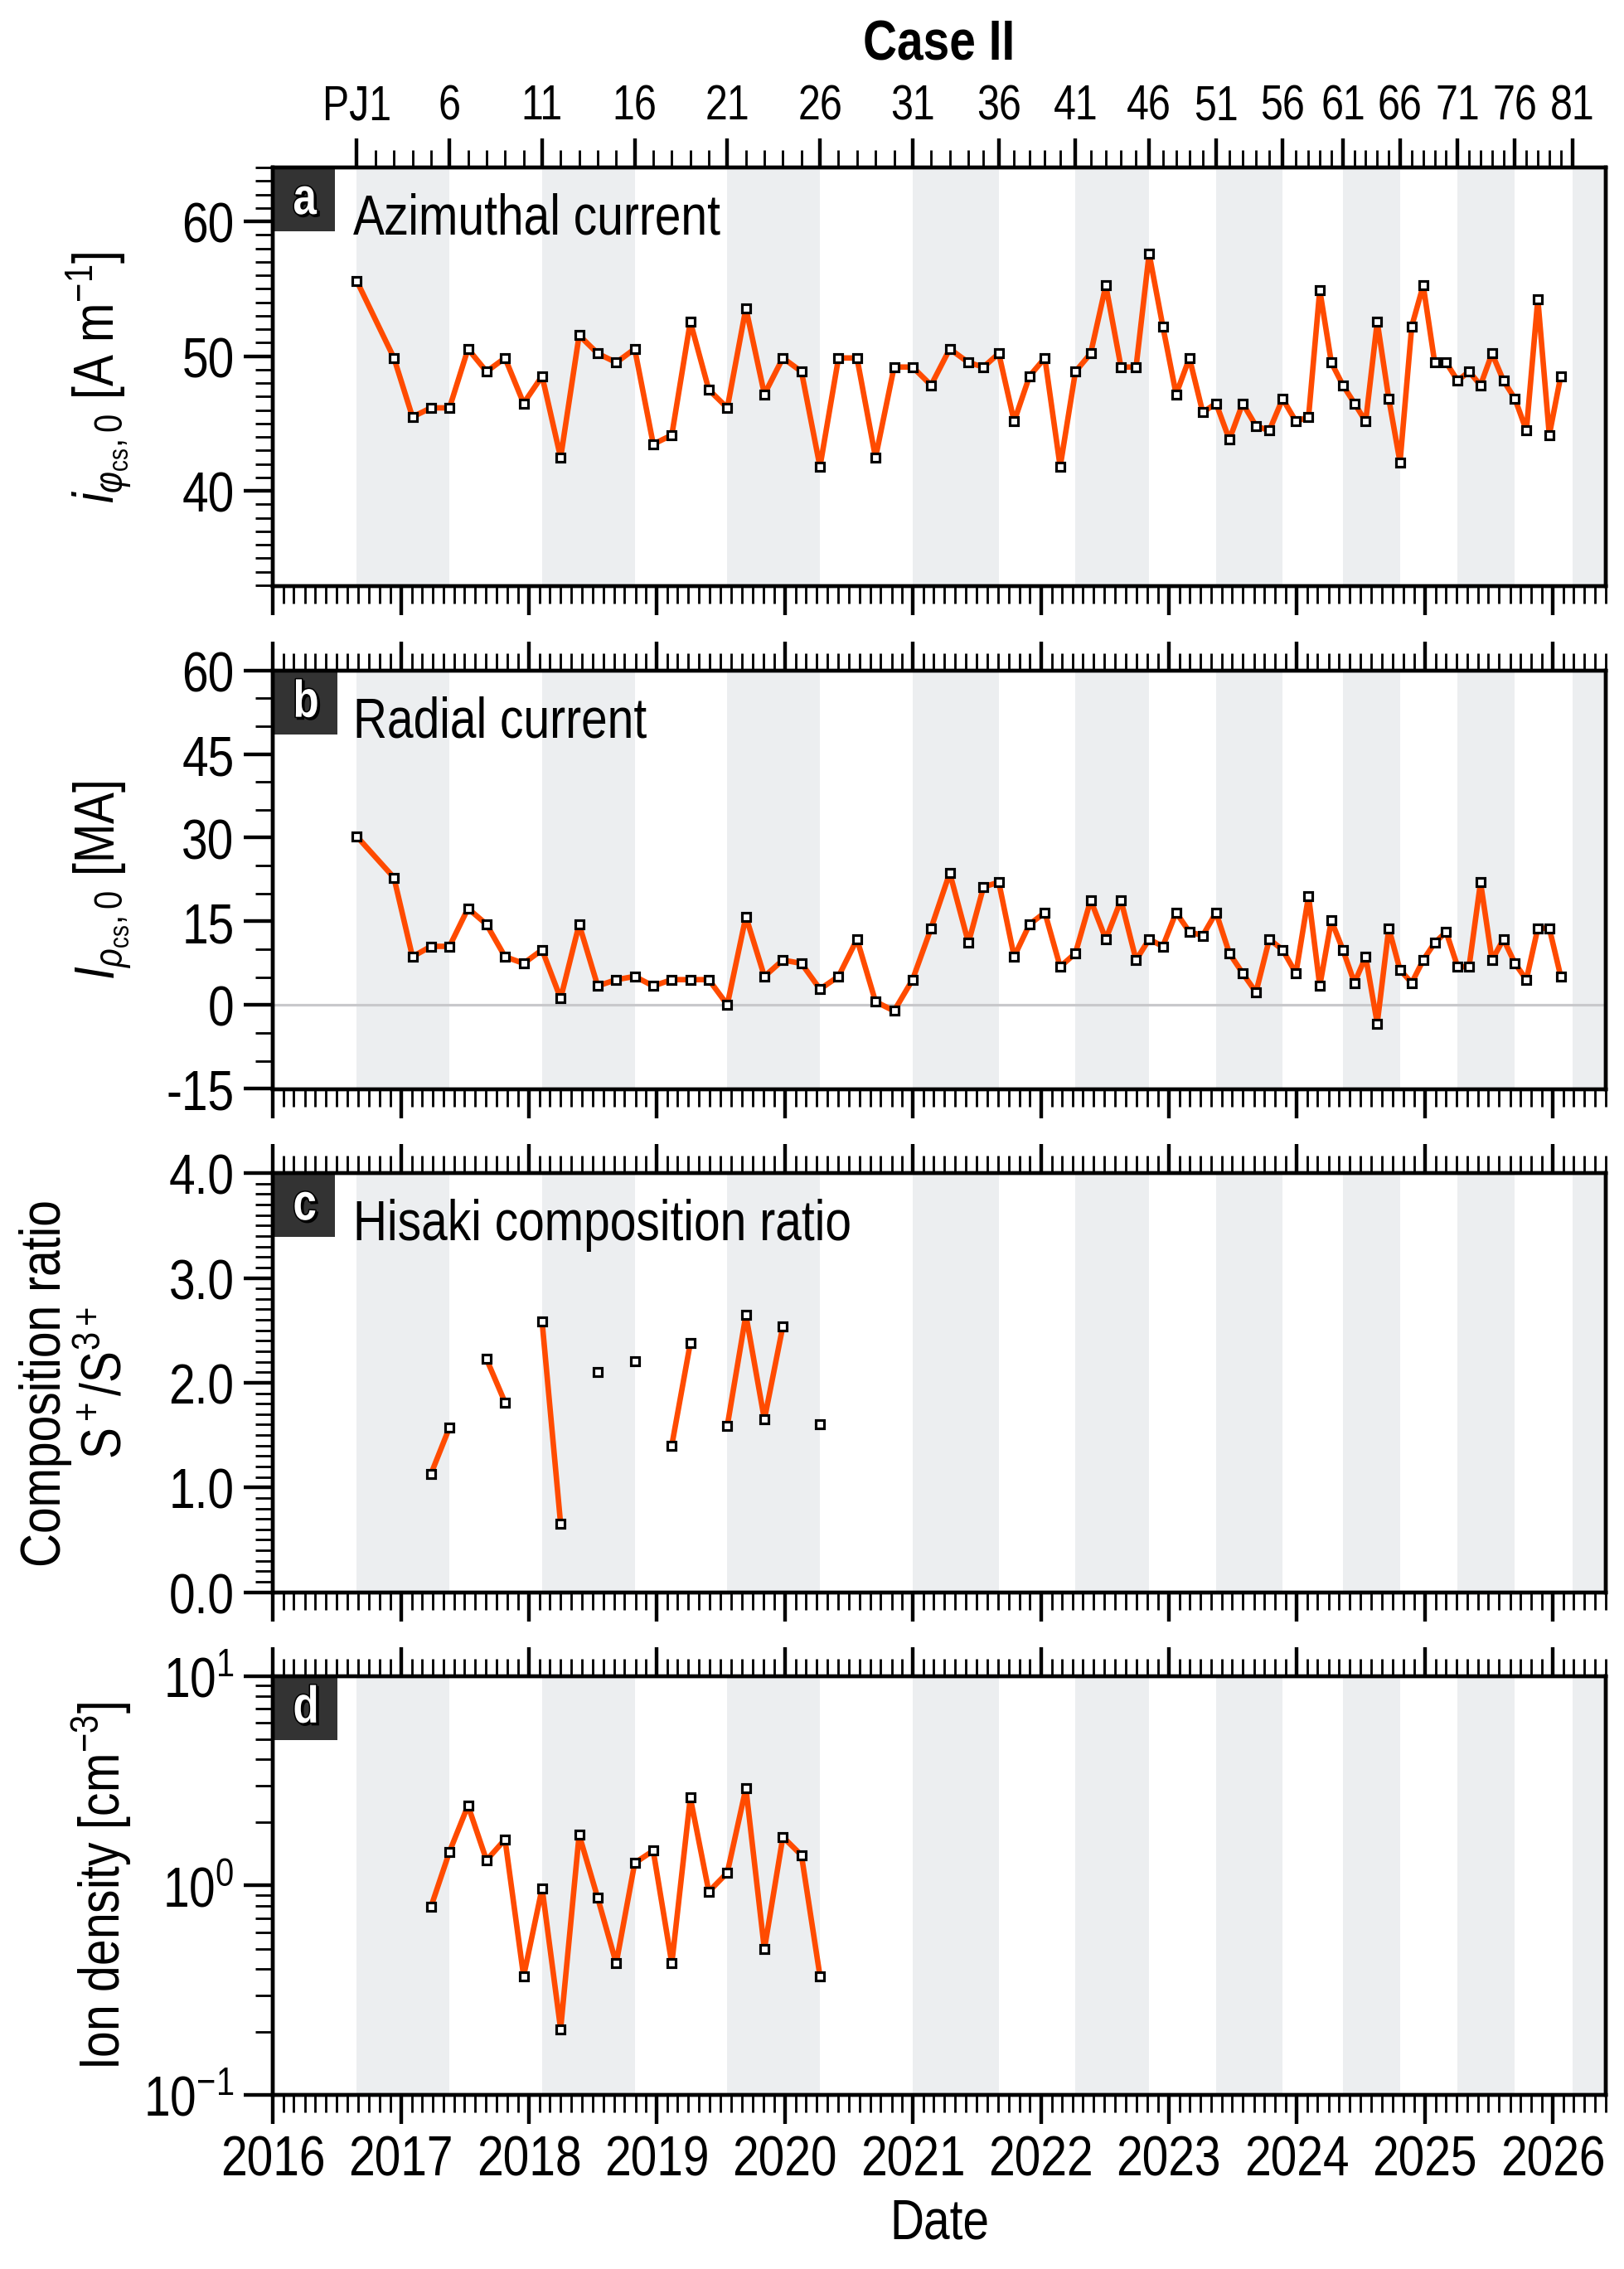

Mean & standard deviation (all)
i_phi [A m-1]: 48.38275473116932 3.335694637137576
I_rho [MA]: 10.033388761574646 6.265121970466022
RMS [nT]: 4.313726238484319 1.2086461079961925
Mean & standard deviation (first 40 perijoves)
i_phi [A m-1]: 48.204112718964204 3.133318226724576
I_rho [MA]: 9.888305099120284 7.190844701748111
RMS [nT]: 4.227472398737987 1.110394353068211


In [10]:
# %% ================================
# 横軸: date / 縦軸: 電流の沿磁力線積分値
# ===================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(8.3, 11.5), ticksize=1.5, dpi='L')
F.hspace = 0.2
F.initialize()

sxmin = '2016-01-01'
sxmax = '2026-06-01'
xmin = datetime.datetime.strptime(sxmin, '%Y-%m-%d')
xmax = datetime.datetime.strptime(sxmax, '%Y-%m-%d')
xticks = [datetime.datetime.strptime('2016-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2017-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2018-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2019-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2020-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2021-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2022-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2023-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2024-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2025-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2026-01-01', '%Y-%m-%d')]
xticklabels = ['2016', '2017', '2018', '2019', '2020',
               '2021', '2022', '2023', '2024', '2025',
               '2026']
F.set_xaxis(label='Date',
            min=xmin, max=xmax,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=12,
            format='%Y-%m-%d')
ticklabels = F.ax[3].get_xticklabels()
ticklabels[0].set_ha('center')
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=32.9, max=64.0,
            ticks=np.arange(40, 60+1, 10),
            ticklabels=np.arange(40, 60+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-15.1, max=60,
            ticks=np.arange(-15, 60+1, 15),
            ticklabels=np.arange(-15, 60+1, 15),
            minor_num=3,)
F.set_yaxis(ax_idx=2,
            label='Composition ratio\nS$^+$/S$^{3+}$',
            min=0.0, max=4,
            ticks=np.arange(0, 4+0.1, 1),
            ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)
F.set_yaxis(ax_idx=3,
            label=r'Ion density [cm$^{-3}$]',
            yscale='log',
            min=0.1, max=10.0,
            # ticks=np.arange(0, 4+0.1, 1),
            # ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

# Azimuthal current
pj_2_date = []
for i in range(f0[:, 0].size):
    pj_2_date += [JUNO_PJ_TIMES[int(f0[i, 0])-1]]
F.ax[0].plot(pj_2_date, f0[:, 1]*1E+6,
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# Radial current
F.ax[1].plot(pj_2_date, f0[:, 3],
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# Hisaki composition ratio
F.ax[2].plot(hisaki_time, hisaki_R_comp,
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# Juno heavy ion density (20 RJ)
F.ax[3].plot(hisaki_time, juno_heavy_ion,
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# PJ numbers on the top horizontal axis
PJax = F.ax[0].twiny()
PJax.set_xlim(xmin, xmax)
PJax.set_xticks(JUNO_PJ_TIMES[::5])
PJax.set_xticklabels(JUNO_PJ_LABELS[::5], fontsize=F.fontsize*0.85)
PJax.xaxis.set_minor_locator(FixedLocator(mdates.date2num(JUNO_PJ_TIMES)))
PJax.tick_params('y', grid_zorder=-10)
PJax.set_title(case, weight='bold')

# Shades in each 5 perijove
for i in range(4):
    F.ax[i].axvspan(JUNO_PJ_TIMES[0], JUNO_PJ_TIMES[5],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[10], JUNO_PJ_TIMES[15],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[20], JUNO_PJ_TIMES[25],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[30], JUNO_PJ_TIMES[35],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[40], JUNO_PJ_TIMES[45],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[50], JUNO_PJ_TIMES[55],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[60], JUNO_PJ_TIMES[65],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[70], JUNO_PJ_TIMES[75],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[80], xmax,
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[1].axhline(y=0, color=UC.lightgray, linewidth=1.0, zorder=0.9)

F.ax[0].text(0.06, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.06, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)
F.ax[2].text(0.06, 0.94,
             'Hisaki composition ratio',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[2].transAxes)

"""legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='lower center',
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[0], d=0.7)"""

"""plt.savefig('img/'+dir[8:]+'_time_001.pdf',
            bbox_inches='tight')"""
plt.show()
F.close()
plt.close()

print('Mean & standard deviation (all)')
print('i_phi [A m-1]:', np.mean(f0[:, 1]*1E+6), np.std(f0[:, 1]*1E+6))
print('I_rho [MA]:', np.mean(f0[:, 3]), np.std(f0[:, 3]))
print('RMS [nT]:', np.mean(f0[:, 5]), np.std(f0[:, 5]))

print('Mean & standard deviation (first 40 perijoves)')
print('i_phi [A m-1]:', np.mean(f0[0:39, 1]*1E+6), np.std(f0[0:39, 1]*1E+6))
print('I_rho [MA]:', np.mean(f0[0:39, 3]), np.std(f0[0:39, 3]))
print('RMS [nT]:', np.mean(f0[0:39, 5]), np.std(f0[0:39, 5]))

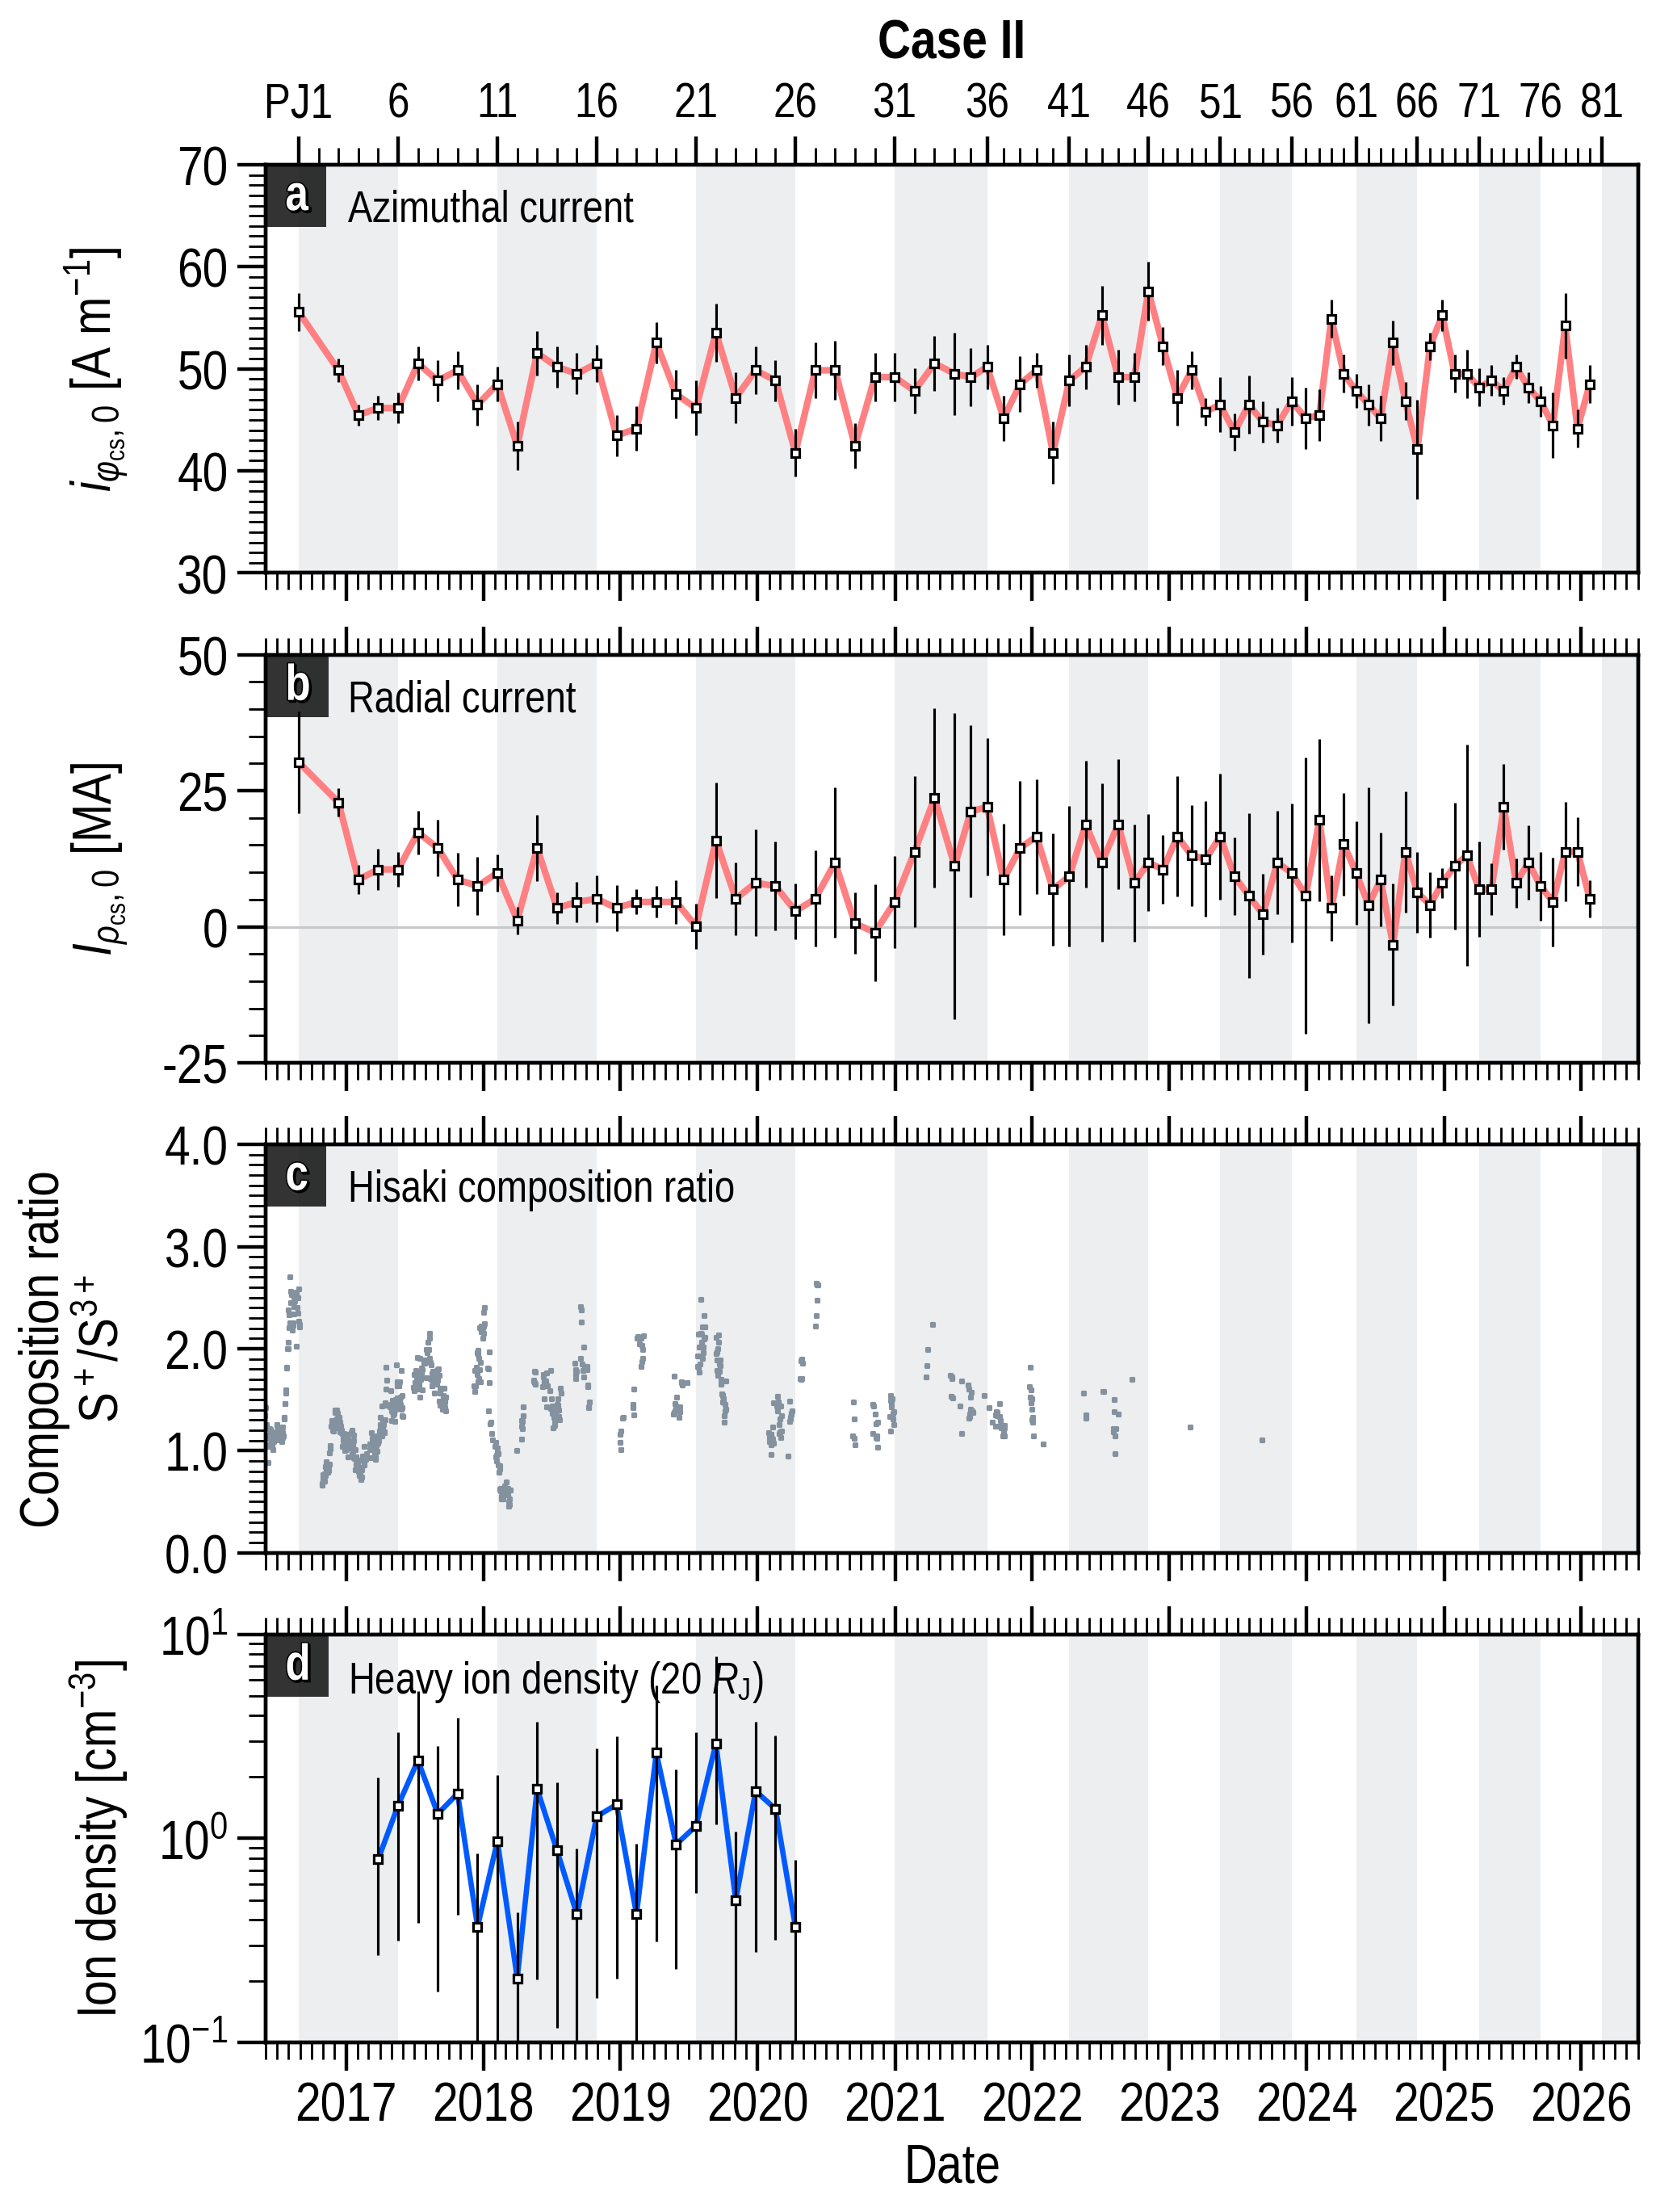

In [11]:
# %% ================================
# 横軸: date / 縦軸: 電流の沿磁力線積分値
# ===================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(8.7, 11.5), ticksize=1.5, dpi='L')
F.hspace = 0.2
F.initialize()

sxmin = '2016-06-01'
sxmax = '2026-06-01'
xmin = datetime.datetime.strptime(sxmin, '%Y-%m-%d')
xmax = datetime.datetime.strptime(sxmax, '%Y-%m-%d')
xticks = [datetime.datetime.strptime('2017-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2018-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2019-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2020-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2021-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2022-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2023-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2024-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2025-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2026-01-01', '%Y-%m-%d')]
xticklabels = ['2017', '2018', '2019', '2020',
               '2021', '2022', '2023', '2024', '2025',
               '2026']
F.set_xaxis(label='Date',
            min=xmin, max=xmax,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=12,
            format='%Y-%m-%d')
ticklabels = F.ax[3].get_xticklabels()
ticklabels[0].set_ha('center')
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=50,
            ticks=np.arange(-25, 50+1, 25),
            ticklabels=np.arange(-25, 50+1, 25),
            minor_num=5,)
F.set_yaxis(ax_idx=2,
            label='Composition ratio\nS$^+$/S$^{3+}$',
            min=0.0, max=4,
            ticks=np.arange(0, 4+0.1, 1),
            ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)
F.set_yaxis(ax_idx=3,
            label=r'Ion density [cm$^{-3}$]',
            yscale='log',
            min=0.1, max=10.0,
            # ticks=np.arange(0, 4+0.1, 1),
            # ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

# Azimuthal current
pj_2_date = []
for i in range(f0[:, 0].size):
    pj_2_date += [JUNO_PJ_TIMES[int(f0[i, 0])-1]]
F.ax[0].plot(pj_2_date, f0[:, 1]*1E+6,
             marker='s', color=linecolor, markersize=0,
             linewidth=2.6, markeredgecolor='k', markerfacecolor='w',
             zorder=3)
F.ax[0].errorbar(x=pj_2_date, y=f0[:, 1]*1E+6,
                 yerr=f0[:, 2]*1E+6, color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)

# Radial current
F.ax[1].plot(pj_2_date, f0[:, 3],
             marker='s', color=linecolor, markersize=0,
             linewidth=2.6, markeredgecolor='k', markerfacecolor='w',
             zorder=2)
F.ax[1].errorbar(x=pj_2_date, y=f0[:, 3],
                 yerr=f0[:, 4], color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)

# Hisaki composition ratio
nan = np.isnan(hisaki_R_comp)
"""F.ax[2].plot(hisaki_time[~nan], hisaki_R_comp[~nan],
             marker='s', color=UC.blue, markersize=0,
             linewidth=1.5, markeredgecolor='k', markerfacecolor='w',
             zorder=2)
F.ax[2].errorbar(x=hisaki_time[~nan], y=hisaki_R_comp[~nan],
                 yerr=hisaki_R_comp_err[~nan], color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)"""
F.ax[2].scatter(hisaki_1day_datetime, hisaki_1day_R_comp_dusk,
                s=2, marker='s', c=UC.gray)
# F.ax[2].scatter(hisaki_1day_datetime, hisaki_1day_R_comp_dawn,
#                 s=2, marker='s', c=UC.gray)

# Juno heavy ion density (20 RJ)
F.ax[3].plot(hisaki_time, juno_heavy_ion,
             marker='s', color=UC.blue, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)
F.ax[3].errorbar(x=hisaki_time, y=juno_heavy_ion,
                 yerr=[juno_heavy_ion_err_n, juno_heavy_ion_err_p],
                 color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)

# PJ numbers on the top horizontal axis
PJax = F.ax[0].twiny()
PJax.set_xlim(xmin, xmax)
PJax.set_xticks(JUNO_PJ_TIMES[::5])
PJax.set_xticklabels(JUNO_PJ_LABELS[::5], fontsize=F.fontsize*0.87)
PJax.xaxis.set_minor_locator(FixedLocator(mdates.date2num(JUNO_PJ_TIMES)))
PJax.tick_params('y', grid_zorder=-10)
PJax.set_title(case, weight='bold')

# Shades in each 5 perijove
for i in range(4):
    F.ax[i].axvspan(JUNO_PJ_TIMES[0], JUNO_PJ_TIMES[5],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[10], JUNO_PJ_TIMES[15],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[20], JUNO_PJ_TIMES[25],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[30], JUNO_PJ_TIMES[35],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[40], JUNO_PJ_TIMES[45],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[50], JUNO_PJ_TIMES[55],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[60], JUNO_PJ_TIMES[65],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[70], JUNO_PJ_TIMES[75],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[80], xmax,
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[1].axhline(y=0, color=UC.lightgray, linewidth=1.0, zorder=0.9)

F.ax[0].text(0.06, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize*0.8,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.06, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize*0.8,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)
F.ax[2].text(0.06, 0.94,
             'Hisaki composition ratio',
             color='k',
             fontsize=F.fontsize*0.8,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[2].transAxes)
F.ax[3].text(0.06, 0.94,
             r'Heavy ion density (20 $R_{\rm J}$)',
             color='k',
             fontsize=F.fontsize*0.8,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[3].transAxes)

"""legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='lower center',
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[0], d=0.7)"""

plt.show()
F.close()
plt.close()

In [12]:
def spearman_manual(x, y):
    """スピアマン順位相関係数を手動実装"""
    n = len(x)
    # 順位に変換（同順位は平均順位）
    rank_x = stats.rankdata(x)
    rank_y = stats.rankdata(y)
    # 順位の差
    d = rank_x - rank_y
    rho = 1 - (6 * np.sum(d**2)) / (n * (n**2 - 1))
    return rho

Correlation coef: 0.8150357552134162
p value: 0.0002140831456180697
Spearman r: 0.8018017837259407 0.0003242241561708694


/opt/homebrew/Caskroom/miniforge/base/envs/py3104/lib/python3.10/site-packages/matplotlib/axes/_axes.py:1105: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/opt/homebrew/Caskroom/miniforge/base/envs/py3104/lib/python3.10/site-packages/matplotlib/axes/_axes.py:1106: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])
/opt/homebrew/Caskroom/miniforge/base/envs/py3104/lib/python3.10/site-packages/matplotlib/axes/_axes.py:1185: RuntimeWarning: All-NaN axis encountered
  miny = np.nanmin(masked_verts[..., 1])
/opt/homebrew/Caskroom/miniforge/base/envs/py3104/lib/python3.10/site-packages/matplotlib/axes/_axes.py:1186: RuntimeWarning: All-NaN axis encountered
  maxy = np.nanmax(masked_verts[..., 1])


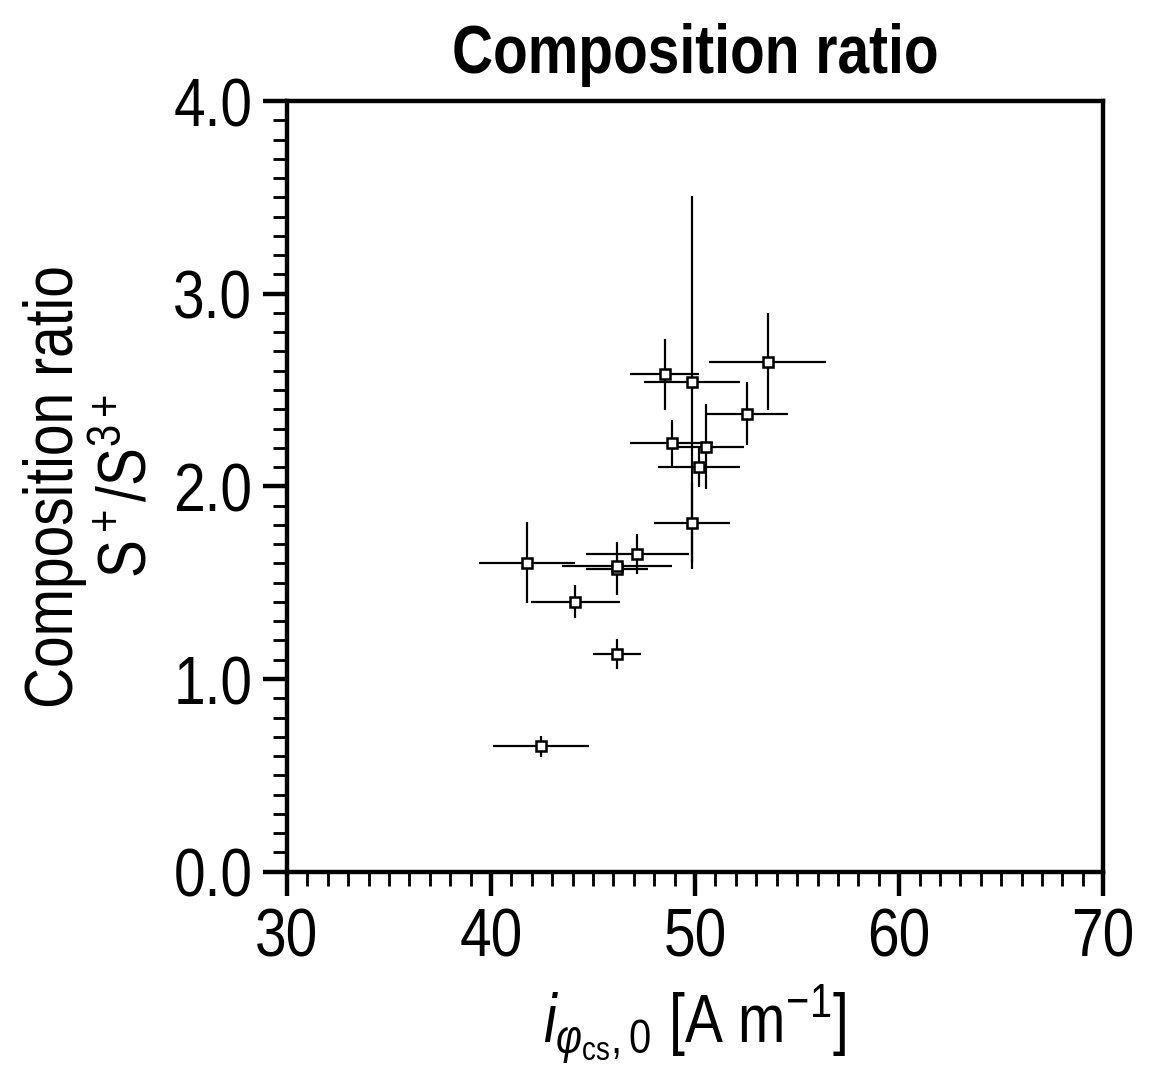

In [13]:
# %% ==================================
# 横軸: i_phi0 / 縦軸: 組成比
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.6), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label='Composition ratio\nS$^+$/S$^{3+}$',
            min=0.0, max=4,
            ticks=np.arange(0, 4+0.1, 1),
            ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

F.ax.set_title('Composition ratio', fontweight='bold')

azimuthal_current_hisaki = []
for j in range(f0[:, 1].size):
    for i in range(hisaki_pj.size):
        if f0[j, 0] == hisaki_pj[i]:
            azimuthal_current_hisaki += [f0[j, 1]*1E-6]
            F.ax.errorbar(x=f0[j, 1]*1E+6, y=hisaki_R_comp[i],
                          xerr=f0[j, 2]*1E+6,
                          yerr=hisaki_R_comp_err[i],
                          color='k',
                          elinewidth=0.7, linewidth=0.,
                          marker='s', markersize=2.9,
                          markeredgecolor='k', markerfacecolor='w',
                          markeredgewidth=0.8,
                          zorder=4)

# Normal correlation coefficient
azimuthal_current_hisaki = np.array(azimuthal_current_hisaki)
nan = np.isnan(hisaki_R_comp)
coef, p_value = stats.pearsonr(
    azimuthal_current_hisaki[~nan],
    hisaki_R_comp[~nan]
)
print('Correlation coef:', coef)
print('p value:', p_value)

# Spearman
x_data = azimuthal_current_hisaki[~nan]
y_data = hisaki_R_comp[~nan]
spearman_r, p = stats.spearmanr(x_data, y_data)
print('Spearman r:', spearman_r, p)

Correlation coef: 0.4685263908773532
p value: 0.07814593224160939
Spearman r: 0.4153998867529178 0.12360264801296476


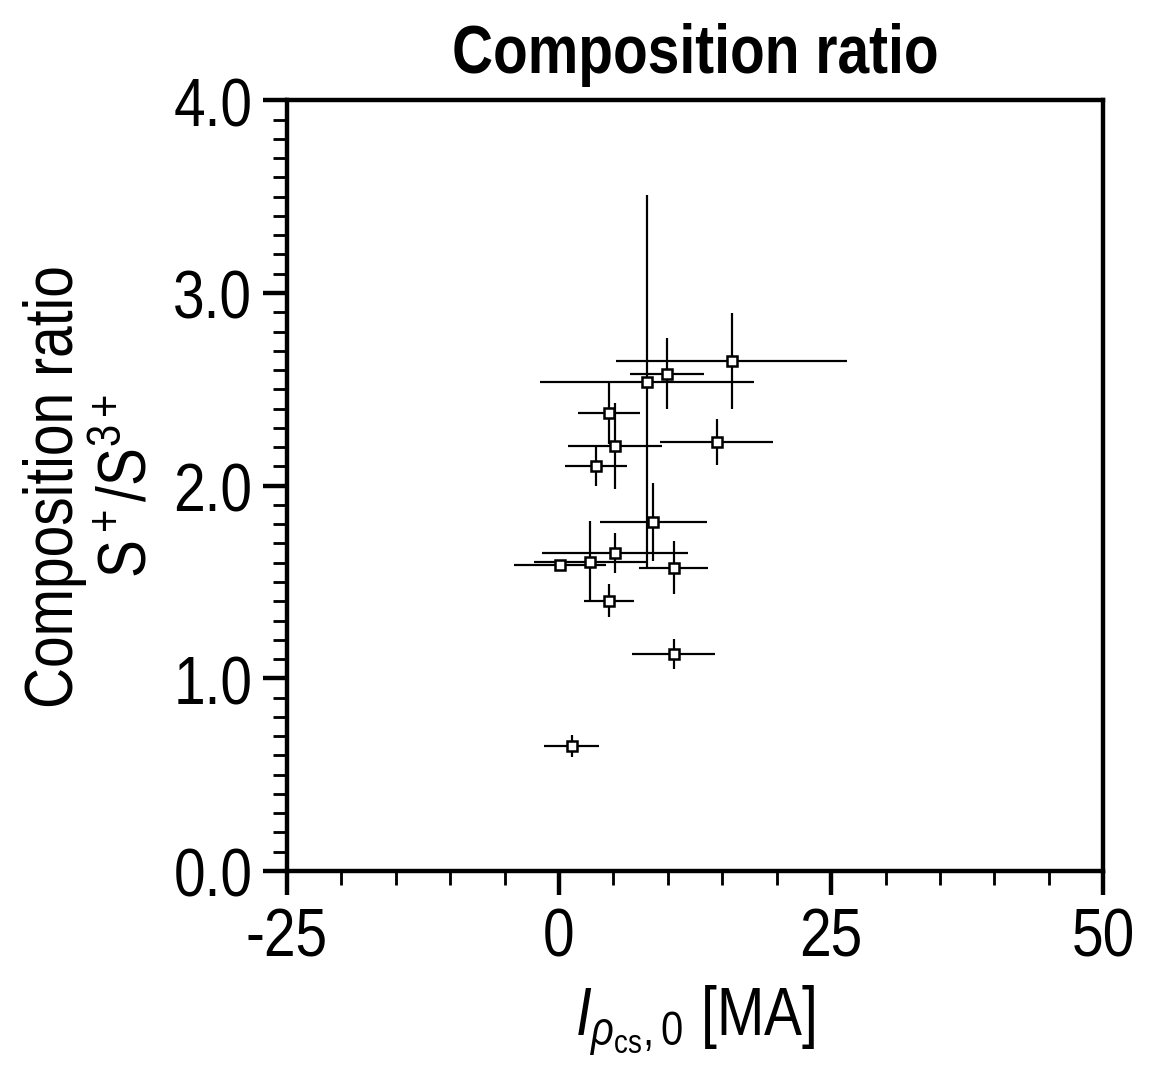

In [14]:
# %% ==================================
# 横軸: I_rho0 / 縦軸: 組成比
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.6), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=50,
            ticks=np.arange(-25, 50+1, 25),
            ticklabels=np.arange(-25, 50+1, 25),
            minor_num=5,)
F.set_yaxis(ax_idx=1,
            label='Composition ratio\nS$^+$/S$^{3+}$',
            min=0.0, max=4,
            ticks=np.arange(0, 4+0.1, 1),
            ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

radial_current_hisaki = []
for j in range(f0[:, 0].size):
    for i in range(hisaki_pj.size):
        if f0[j, 0] == hisaki_pj[i]:
            radial_current_hisaki += [f0[j, 3]]
            F.ax.errorbar(x=f0[j, 3], y=hisaki_R_comp[i],
                          xerr=f0[j, 4],
                          yerr=hisaki_R_comp_err[i],
                          color='k',
                          elinewidth=0.7, linewidth=0.,
                          marker='s', markersize=2.9,
                          markeredgecolor='k', markerfacecolor='w',
                          markeredgewidth=0.8,
                          zorder=4)

F.ax.set_title('Composition ratio', fontweight='bold')

# Normal correlation coefficient
radial_current_hisaki = np.array(radial_current_hisaki)
nan = np.isnan(hisaki_R_comp)
coef, p_value = stats.pearsonr(
    radial_current_hisaki[~nan],
    hisaki_R_comp[~nan]
)
print('Correlation coef:', coef)
print('p value:', p_value)


# Spearman
x_data = radial_current_hisaki[~nan]
y_data = hisaki_R_comp[~nan]
spearman_r, p = stats.spearmanr(x_data, y_data)
print('Spearman r:', spearman_r, p)

Correlation coef: 0.7220650609356954
p value: 0.00014814633786095974
Spearman r: 0.6908075778726974 0.00037177302091080504


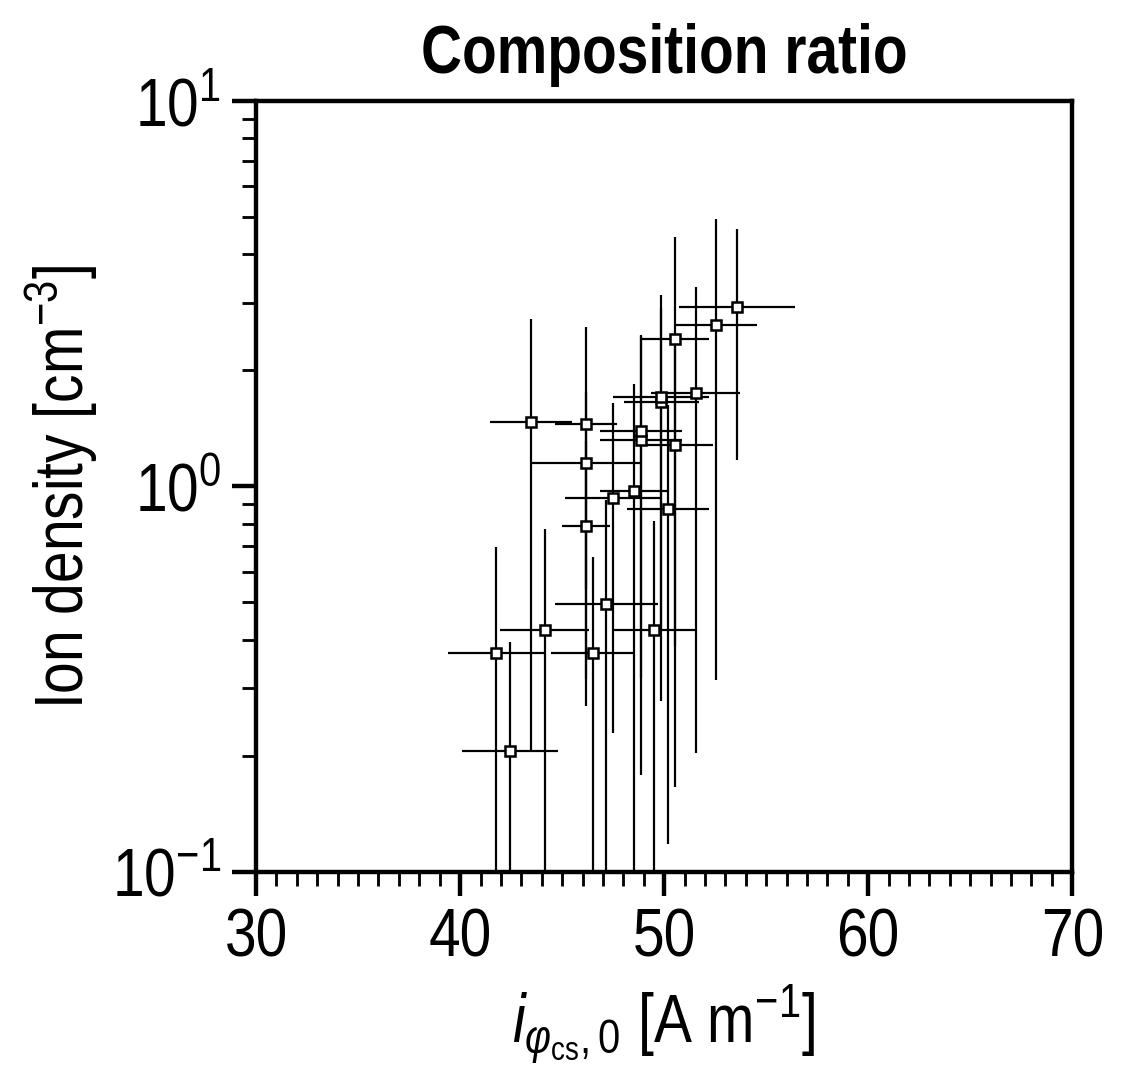

In [15]:
# %% ==================================
# 横軸: i_phi0 / 縦軸: Heavy ion density
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.6), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'Ion density [cm$^{-3}$]',
            yscale='log',
            min=0.1, max=10.0,
            # ticks=np.arange(0, 4+0.1, 1),
            # ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

F.ax.set_title('Composition ratio', fontweight='bold')

azimuthal_current_hisaki = []
for j in range(f0[:, 1].size):
    for i in range(hisaki_pj.size):
        if f0[j, 0] == hisaki_pj[i]:
            azimuthal_current_hisaki += [f0[j, 1]*1E-6]
            F.ax.errorbar(x=f0[j, 1]*1E+6, y=juno_heavy_ion[i],
                          xerr=f0[j, 2]*1E+6,
                          yerr=np.array(
                              [[juno_heavy_ion_err_n[i]], [juno_heavy_ion_err_n[i]]]),
                          color='k',
                          elinewidth=0.7, linewidth=0.,
                          marker='s', markersize=2.9,
                          markeredgecolor='k', markerfacecolor='w',
                          markeredgewidth=0.8,
                          zorder=4)

# Normal correlation coefficient
azimuthal_current_hisaki = np.array(azimuthal_current_hisaki)
nan = np.isnan(juno_heavy_ion)
coef, p_value = stats.pearsonr(
    azimuthal_current_hisaki[~nan],
    juno_heavy_ion[~nan]
)
print('Correlation coef:', coef)
print('p value:', p_value)

# Spearman
x_data = azimuthal_current_hisaki[~nan]
y_data = juno_heavy_ion[~nan]
spearman_r, p = stats.spearmanr(x_data, y_data)
print('Spearman r:', spearman_r, p)

Correlation coef: 0.5814519536902185
p value: 0.004535815061668671
Spearman r: 0.5443769106770235 0.008809611964072667


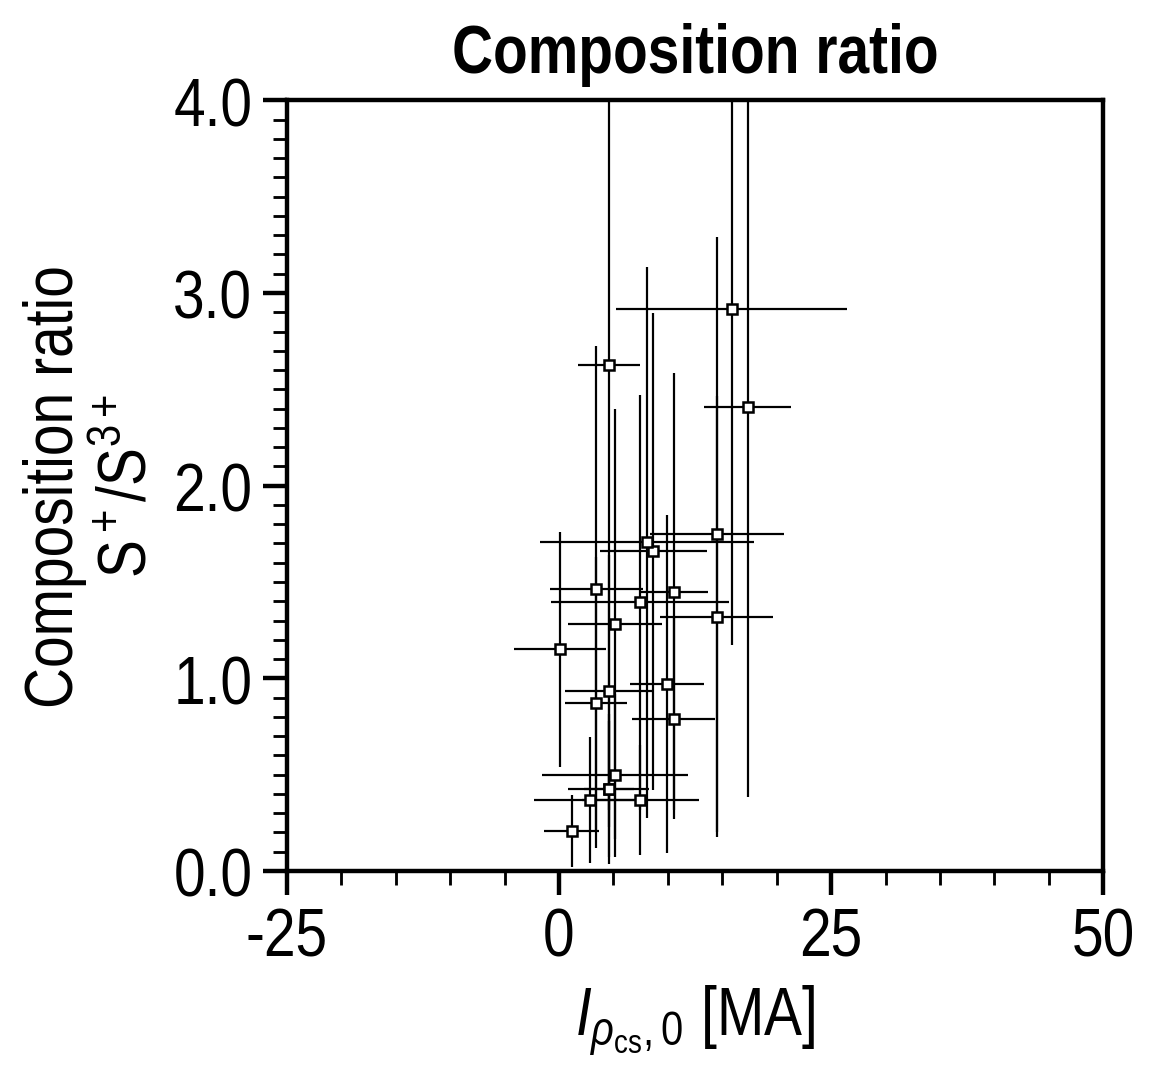

In [16]:
# %% ==================================
# 横軸: I_rho0 / 縦軸: Heavy ion density
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.6), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=50,
            ticks=np.arange(-25, 50+1, 25),
            ticklabels=np.arange(-25, 50+1, 25),
            minor_num=5,)
F.set_yaxis(ax_idx=1,
            label='Composition ratio\nS$^+$/S$^{3+}$',
            min=0.0, max=4,
            ticks=np.arange(0, 4+0.1, 1),
            ticklabels=np.arange(0, 4+0.1, 1),
            minor_num=10,)

radial_current_hisaki = []
for j in range(f0[:, 0].size):
    for i in range(hisaki_pj.size):
        if f0[j, 0] == hisaki_pj[i]:
            radial_current_hisaki += [f0[j, 3]]
            F.ax.errorbar(x=f0[j, 3], y=juno_heavy_ion[i],
                          xerr=f0[j, 4],
                          yerr=np.array(
                              [[juno_heavy_ion_err_n[i]], [juno_heavy_ion_err_n[i]]]),
                          color='k',
                          elinewidth=0.7, linewidth=0.,
                          marker='s', markersize=2.9,
                          markeredgecolor='k', markerfacecolor='w',
                          markeredgewidth=0.8,
                          zorder=4)

F.ax.set_title('Composition ratio', fontweight='bold')

# Normal correlation coefficient
radial_current_hisaki = np.array(radial_current_hisaki)
nan = np.isnan(juno_heavy_ion)
coef, p_value = stats.pearsonr(
    radial_current_hisaki[~nan],
    juno_heavy_ion[~nan]
)
print('Correlation coef:', coef)
print('p value:', p_value)


# Spearman
x_data = radial_current_hisaki[~nan]
y_data = juno_heavy_ion[~nan]
spearman_r, p = stats.spearmanr(x_data, y_data)
print('Spearman r:', spearman_r, p)

Scan complete: dt = 0 to 50 days
  Best dt = 20 days  (r=0.7383, p=9.463e-03, N=11)


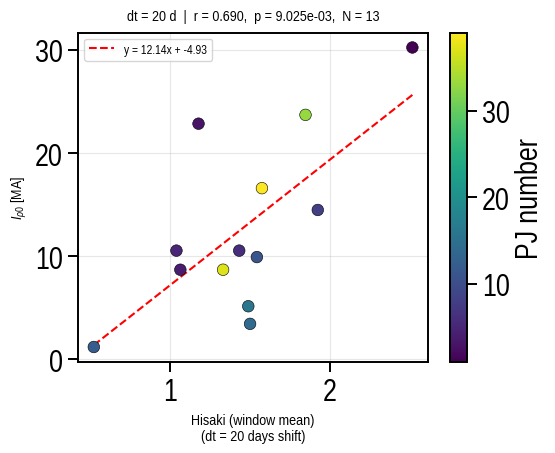

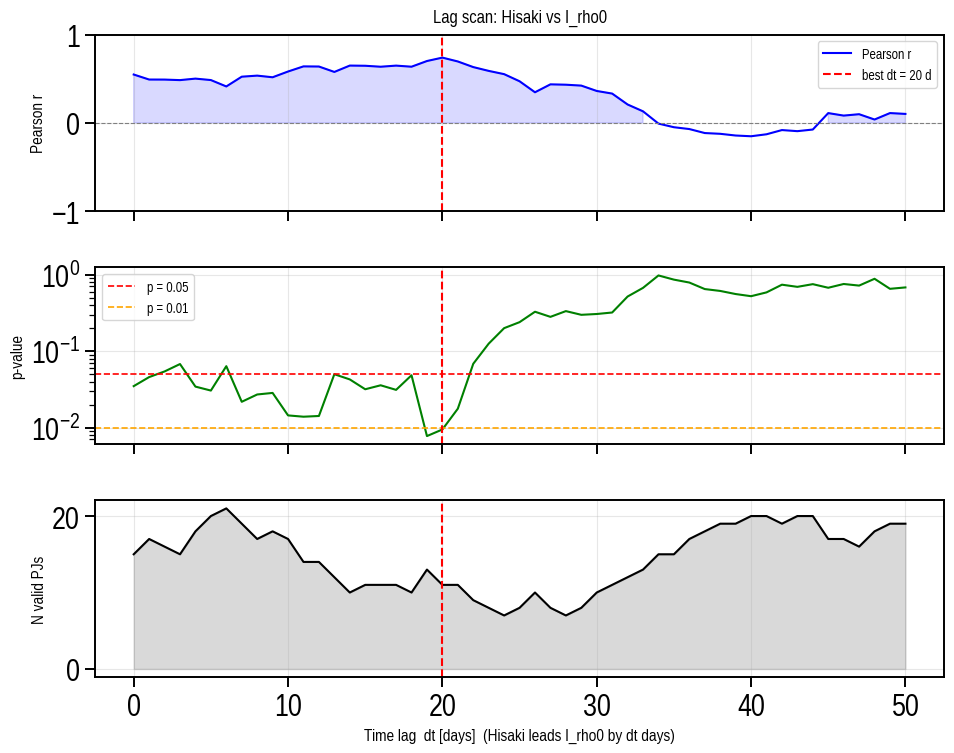

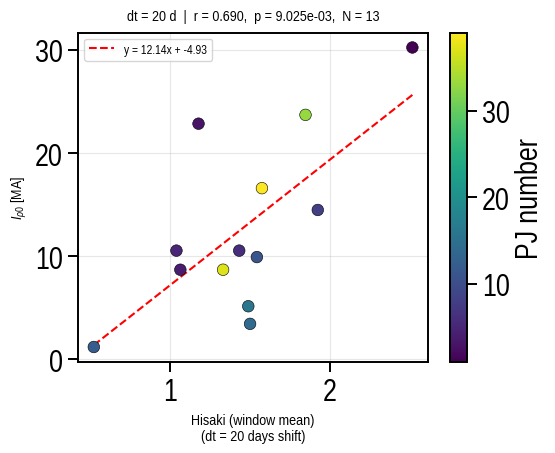

In [17]:
# （lag_correlation.pyと同じフォルダで作業するか、sys.path.appendで追加）
from lag_correlation import make_hisaki_series, scan_lag, find_best_dt
from lag_correlation import plot_lag_scan, plot_scatter_at_best_dt

# --- Hisakiデータ読み込み ---
df = pd.read_csv(
    '/Users/shin/Documents/Research/Hisaki/hisaki_l2p_Slice_check.csv')

# NaNの行を除外してからSeriesを作る
mask = df['R_comp_dusk'].notna()
hisaki_series = make_hisaki_series(
    df.loc[mask, 'datetime'].values,
    df.loc[mask, 'R_comp_dusk'].values
)

# --- JunoのPJデータ ---
pj_df = pd.DataFrame({
    'pj':     PJ_list,
    'date':   pj_2_date,
    'I_rho0': f0[:, 3],
})

# --- スキャン・プロット ---
result_df = scan_lag(
    hisaki_series, pj_df,
    dt_min=0, dt_max=50,
    min_pts=3,   # 6日窓で3点以上必要
)
best = find_best_dt(result_df)
plot_lag_scan(result_df, best_dt=best['dt'])
plot_scatter_at_best_dt(hisaki_series, pj_df, int(best['dt']))

In [18]:
# dt=19日周辺の相関の形を確認
print(result_df[result_df['dt'].between(10, 30)].to_string())

    dt         r         p  n_valid
10  10  0.580995  0.014453       17
11  11  0.638962  0.013897       14
12  12  0.637432  0.014200       14
13  13  0.576159  0.049914       12
14  14  0.648109  0.042700       10
15  15  0.646072  0.031745       11
16  16  0.635073  0.035778       11
17  17  0.647709  0.031174       11
18  18  0.635370  0.048371       10
19  19  0.699699  0.007760       13
20  20  0.738347  0.009463       11
21  21  0.694613  0.017690       11
22  22  0.631085  0.068364        9
23  23  0.587988  0.125273        8
24  24  0.551150  0.199716        7
25  25  0.470618  0.239225        8
26  26  0.346034  0.327361       10
27  27  0.435663  0.280608        8
28  28  0.431601  0.333584        7
29  29  0.421411  0.298417        8
30  30  0.360778  0.305748       10


In [19]:
# best dtでの統計を確認
print(best)

dt         20.000000
r           0.738347
p           0.009463
n_valid    11.000000
Name: 20, dtype: float64
